# DETECTIA BIAS-ULUI DIN TEXTE - REGRESIE LOGISTICA VS DISTILBERT

Acest proiect urmareste antrenarea si compararea a doua modele de clasificare a bias-ului din texte.
Dataset-ul utilizat news-media-bias contine texte din surse media si de stiri diverse, pentru o invatare generala, nu specializata pe un anumit tip de informatii.
Modelele implementate in scopul compararii performantei sunt o Regresie Logistica (un model clasic de ML) si DistilBERT (un model de tip Transformer, actual industriei in acest moment).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import seaborn as sns
import re
import html
import time
import random
import datetime

from sklearn.utils import resample
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, precision_score, recall_score

from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from transformers import get_linear_schedule_with_warmup
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from torch.optim import AdamW



In scopul temei sunt relevante doar urmatoarele 2 coloane ale bazei de date alese: 'text' si 'label_bias'.

In [ ]:
FILE_PATH = "/content/drive/MyDrive/PROIECT_PC/news-media-bias.data.csv"
initial_df = pd.read_csv(FILE_PATH, usecols=['text', 'label_bias'], on_bad_lines='skip')
initial_df = initial_df.dropna()
print(f"Total linii initial: {len(initial_df)}")


Total linii initial: 3721220


Fiind date reale preluate din diferite surse media, textele trebuie curatate pentru a elimina o parte din zgomot. Am aplicat 2 tehnici de curatare diferite, corespunzatoare fiecarui model.

In [ ]:
#CURATAREA DATELOR

def data_cleanup_logreg(text):
  text = str(text).lower()
  text = html.unescape(text)
  text = re.sub(r'@\w+', '', text)
  text = re.sub(r'http\S+|www\S+', '', text)
  text = re.sub(r'[^a-z\s]', '', text)
  text = re.sub(r'\s+', ' ', text).strip()
  return text

def data_cleanup_distilbert(text):
  text = str(text)
  text = html.unescape(text)
  text = re.sub(r'@\w+', '', text)
  text = re.sub(r'http\S+|www\S+', '', text)
  text = re.sub(r'[^\w\s.,!?;:\'\'-]', '', text)
  text = re.sub(r'\s+', ' ', text).strip()
  return text

initial_df['text_logreg'] = initial_df['text'].apply(data_cleanup_logreg)
initial_df['text_distilbert'] = initial_df['text'].apply(data_cleanup_distilbert)

df_pool = initial_df[initial_df['text_logreg'].str.len() > 3].copy()

label_mapping = {'biased': 1, 'Non-biased': 0}
df_pool['label'] = df_pool['label_bias'].map(label_mapping)

print(f"Total linii pre dropna: {len(df_pool)}")

df_pool = df_pool.dropna(subset=['label'])

print(f"Total linii post dropna: {len(df_pool)}")

Total linii pre dropna: 3708964
Total linii post dropna: 3684168


Am extras un esantion de 100k linii, echilibrat 50/50 pentru a evita interferenta cu acuratetea.

In [ ]:
#ESANTIONARE

SAMPLE_SIZE = 100000
df_biased = df_pool[df_pool.label == 1]
df_nonbiased = df_pool[df_pool.label == 0]

print(f"Total linii biased: {len(df_biased)}")
print(f"Total linii nonbiased: {len(df_nonbiased)}")

df_sample = pd.concat([
    resample(df_biased, replace=False, n_samples=SAMPLE_SIZE//2, random_state=1),
    resample(df_nonbiased, replace=False, n_samples=SAMPLE_SIZE//2, random_state=1)
])
df_sample = df_sample.sample(frac=1, random_state=1).reset_index(drop=True)

print(f"Total linii esantion: {len(df_sample)}")
print(f"Total linii biased esantion: {len(df_sample[df_sample.label == 1])}")
print(f"Total linii nonbiased esantion: {len(df_sample[df_sample.label == 0])}")

Total linii biased: 794914
Total linii nonbiased: 2889254
Total linii esantion: 100000
Total linii biased esantion: 50000
Total linii nonbiased esantion: 50000


Am realizat impartirea esantionului in date de antrenare si date de testare.

In [ ]:
#TRAIN TEST SPLIT
X_train_df, X_test_df, y_train, y_test = train_test_split(
    df_sample[['text_logreg', 'text_distilbert']],
    df_sample['label'],
    test_size=0.2,
    random_state=1,
    stratify=df_sample['label']
)
print(f"Train: {len(X_train_df)}, Test: {len(X_test_df)}")

X_train_logreg = X_train_df['text_logreg']
X_test_logreg = X_test_df['text_logreg']

X_train_distilbert = X_train_df['text_distilbert']
X_test_distilbert = X_test_df['text_distilbert']

Train: 80000, Test: 20000


Analiza lungimii textelor confirma ca textele au suficient continut pentru extragerea trasaturilor semantice. Este esentiala pentru calibrarea parametrilor si pentru intelegerea performantei modelelor.

Metrica               | LogReg (Curățat)      | DistilBERT (Natural) 
----------------------------------------------------------------------
Medie (Mean)          | 27.0                  | 27.3                 
Mediană               | 15.0                  | 15.0                 
Minim                 | 1                     | 1                    
Maxim                 | 876                   | 876                  
90% din date sub      | 65 cuvinte            | 66 cuvinte
99% din date sub      | 169 cuvinte           | 171 cuvinte


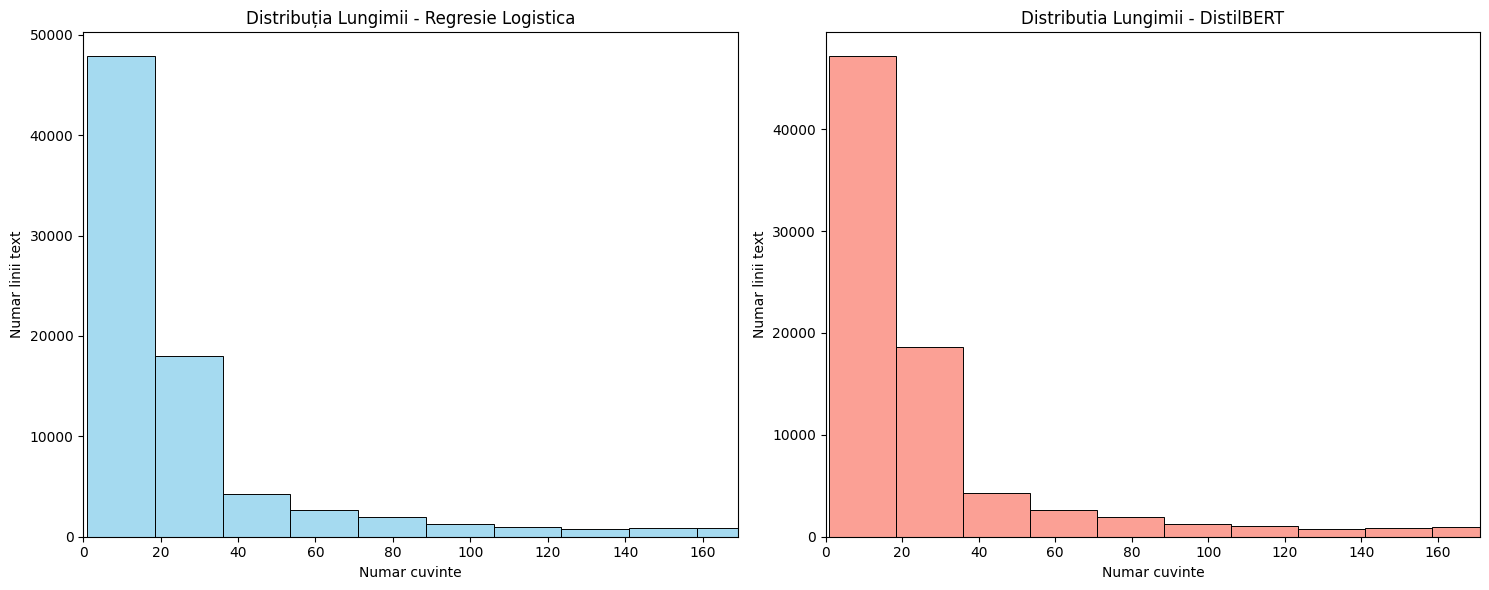

In [ ]:
#ANALIZA NUMARULUI DE CUVINTE

len_logreg = X_train_logreg.str.split().str.len()
len_distilbert = X_train_distilbert.str.split().str.len()

print(f"{'Metrica':<21} | {'LogReg':<21} | {'DistilBERT':<21}")
print("-" * 70)
print(f"{'Medie':<21} | {len_logreg.mean():<21.1f} | {len_distilbert.mean():<21.1f}")
print(f"{'Mediana':<21} | {len_logreg.median():<21.1f} | {len_distilbert.median():<21.1f}")
print(f"{'Minim':<21} | {len_logreg.min():<21} | {len_distilbert.min():<21}")
print(f"{'Maxim':<21} | {len_logreg.max():<21} | {len_distilbert.max():<21}")
print(f"{'90% din date sub':<21} | {len_logreg.quantile(0.90):.0f} cuvinte            | {len_distilbert.quantile(0.90):.0f} cuvinte")
print(f"{'99% din date sub':<21} | {len_logreg.quantile(0.99):.0f} cuvinte           | {len_distilbert.quantile(0.99):.0f} cuvinte")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

#vizualizare regresie

sns.histplot(len_logreg, bins=50, color='skyblue', edgecolor='black', ax=axes[0])
axes[0].set_title('Distribuția Lungimii - Regresie Logistica')
axes[0].set_xlabel('Numar cuvinte')
axes[0].set_ylabel('Numar linii text')
axes[0].set_xlim(0, len_logreg.quantile(0.99))

#vizualizare distilbert

sns.histplot(len_distilbert, bins=50, color='salmon', edgecolor='black', ax=axes[1])
axes[1].set_title('Distributia Lungimii - DistilBERT')
axes[1].set_xlabel('Numar cuvinte')
axes[1].set_ylabel('Numar linii text')
axes[1].set_xlim(0, len_distilbert.quantile(0.99))

plt.tight_layout()
plt.show()

##REGRESIA LOGISTICA

Regresia Logistica este un model clasic de ML, care, combinat cu vectorizarea TF-IDF (Term Frequency-Inverse Document Frequency), este eficient in identificarea si ponderarea cuvintelor cheie. Foloseste putine resurse si timp si ofera un baseline pentru evaluarea modelelor mai complexe.

Pentru a determina numarul optim de de cuvinte pe care modelul le pastreaza in vocabular, am testat urmatoarele valori pentru parametrul max_features.


Valoare: 20000 | Acuratete: 0.8530 | Timp: 14.91s


 Matrice de confuzie
[[8301 1699]
 [1240 8760]]


 Raport de Clasificare:
                precision    recall  f1-score   support

Non-biased (0)       0.87      0.83      0.85     10000
    Biased (1)       0.84      0.88      0.86     10000

      accuracy                           0.85     20000
     macro avg       0.85      0.85      0.85     20000
  weighted avg       0.85      0.85      0.85     20000

--------------------------------------------------

Valoare: 30000 | Acuratete: 0.8530 | Timp: 8.49s


 Matrice de confuzie
[[8304 1696]
 [1244 8756]]


 Raport de Clasificare:
                precision    recall  f1-score   support

Non-biased (0)       0.87      0.83      0.85     10000
    Biased (1)       0.84      0.88      0.86     10000

      accuracy                           0.85     20000
     macro avg       0.85      0.85      0.85     20000
  weighted avg       0.85      0.85      0.85     20000

------------------

/tmp/ipython-input-3530710235.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


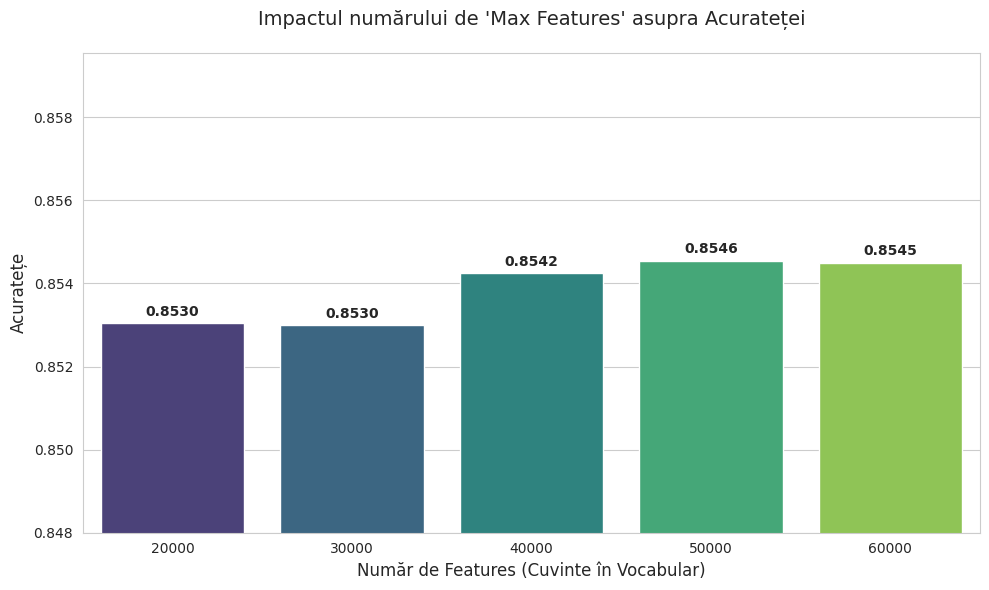

In [ ]:
#EXPERIMENT MAX_FEATURES

test_vals = [20000, 30000, 40000, 50000, 60000]
res = []

for val in test_vals:
  start_time = time.time()

  #vectorizare
  temp_vect = TfidfVectorizer(
      max_features=val,
      min_df=5,
      max_df=0.9,
      ngram_range=(1, 2)
  )

  X_train_vect = temp_vect.fit_transform(X_train_logreg)
  X_test_vect = temp_vect.transform(X_test_logreg)

  #antrenare

  temp_model = LogisticRegression(max_iter=1000, random_state=1)
  temp_model.fit(X_train_vect, y_train)

  #evaluare

  y_pred = temp_model.predict(X_test_vect)
  acc = accuracy_score(y_test, y_pred)

  duration = time.time() - start_time

  res.append({'features': val, 'accuracy': acc, 'time': duration})
  print("")
  print(f"Valoare: {val} | Acuratete: {acc:.4f} | Timp: {duration:.2f}s")
  print("\n\n Matrice de confuzie")
  print(confusion_matrix(y_test, y_pred))
  print("\n\n Raport de Clasificare:")
  print(classification_report(y_test, y_pred, target_names=['Non-biased (0)', 'Biased (1)']))
  print('-' *50)

#vizualizare
# 1. Transformăm lista de rezultate în DataFrame
df_exp = pd.DataFrame(res)

# 2. Setări vizuale (Stilul "Clean")
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# 3. Creăm Graficul de Acuratețe
# Folosim o paletă progresivă (de la deschis la închis) pentru a sugera creșterea numărului de features
ax = sns.barplot(
    data=df_exp,
    x="features",
    y="accuracy",
    palette="viridis"
)

# 4. Adăugăm etichetele pe bare
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3, fontsize=10, fontweight='bold')

# 5. Ajustăm limitele axei Y pentru a vedea diferențele fine
# (Dacă lăsăm de la 0, toate barele vor părea egale)
min_acc = df_exp['accuracy'].min()
max_acc = df_exp['accuracy'].max()
plt.ylim(min_acc - 0.005, max_acc + 0.005)

# 6. Titluri și etichete
plt.title("Impactul numarului de 'Max Features' asupra Acuratetei", fontsize=14, pad=20)
plt.xlabel("Numar de Features", fontsize=12)
plt.ylabel("Acuratete", fontsize=12)

plt.tight_layout()
plt.show()

Am ales valoarea 50000, deoarece modelul atinge performanta maxima cu aceasta valoare, iar apoi incepe sa scada.

Accuracy: 0.85455
Matrice de confuzie:
[[8323 1677]
 [1232 8768]]
Raport de clasificare:
                precision    recall  f1-score   support

Non-biased (0)       0.87      0.83      0.85     10000
    Biased (1)       0.84      0.88      0.86     10000

      accuracy                           0.85     20000
     macro avg       0.86      0.85      0.85     20000
  weighted avg       0.86      0.85      0.85     20000



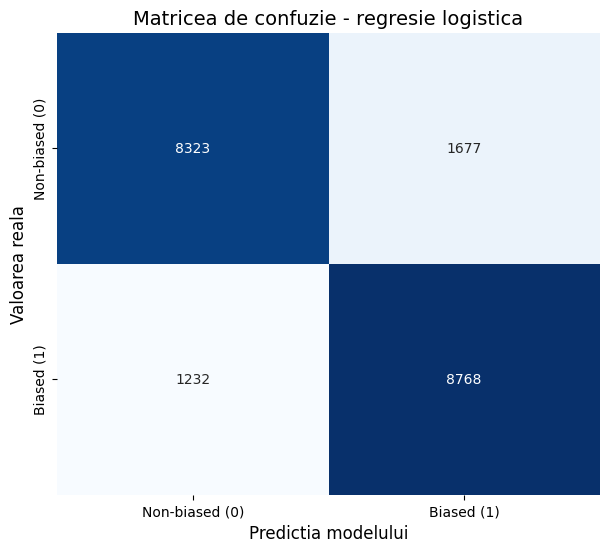

In [ ]:
#REGRESIA LOGISTICA

#vectorizare

vectorizer = TfidfVectorizer(
    max_features=50000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

X_train_vect = vectorizer.fit_transform(X_train_logreg)
X_test_vect = vectorizer.transform(X_test_logreg)

#antrenare

logistic_regression_model = LogisticRegression(max_iter=1000, random_state=1)
logistic_regression_model.fit(X_train_vect, y_train)

#evaluare

y_pred_logreg = logistic_regression_model.predict(X_test_vect)
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)
cm_logreg = confusion_matrix(y_test, y_pred_logreg)
report_logreg = classification_report(y_test, y_pred_logreg, target_names=['Non-biased (0)', 'Biased (1)'])
print(f"Accuracy: {accuracy_logreg}")
print("Matrice de confuzie:")
print(cm_logreg)
print("Raport de clasificare:")
print(report_logreg)

#VIZUALIZARE

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 6))
sns.heatmap(cm_logreg, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Non-biased (0)', 'Biased (1)'],
            yticklabels=['Non-biased (0)', 'Biased (1)'])

plt.xlabel('Predictia modelului', fontsize=12)
plt.ylabel('Valoarea reala', fontsize=12)
plt.title('Matricea de confuzie - regresie logistica', fontsize=14)
plt.show()

###Interpretarea performantei

Regresia Logistica a atins o acuratete de 85.45%, foarte buna pentru un model de acest tip, ceea ce sugereaza prezenta semnificativa a cuvintelor cheie.

Are o precizie echilibrata (0.87 non-biased, 0.84 biased), ceea ce inseamna ca modelul nu favorizeaza o clasa in detrimentul celeilalte.

Recall-ul este mai mare pe clasa biased (0.88 vs 0.83), ceea ce inseamna ca modelul a identificat cu succes 88% din textele biased, un rezultat bun pentru un task de acest tip.

F1-score-ul este consistent(0.85-0.86), indicand si el ca modelul este echilibrat

Matricea de confuzie arata ca modelul face 1677 fals pozitive si 1232 fals negative, ceea ce sugereaza o usoara tendinta de over-flagging, comportament in regula in contextul detectarii bias-ului.

##DISTILBERT


DistilBERT este un model de tip Transformer, ceea ce inseamna ca intelege contextul si relatiile dintre cuvinte, nu doar frecventa termenilor. Acest lucru este esential in identificarea bias-ului, care implica adesea nuante complexe. Am ales versiunea Distil, deoarece ofera un compromis ideal pentru acest proiect: pastreaza aproximativ 97% din performanta modelului BERT si este cu 60% mai rapid si mai putin solicitant din punctul de vedere al resurselor

In [ ]:
device = torch.device("cuda")

#SETAREA SEMINTELOR

seed_val = 1
random.seed(seed_val)
np.random.seed(seed_val)
torch.manual_seed(seed_val)
torch.cuda.manual_seed_all(seed_val)

#TOKENIZARE SI PREGATIREA DATELOR

tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased', do_lower_case=True)
def data_processing(texts, labels, tokenizer, max_len=256):
  input_ids = []
  attention_masks = []

  for text in texts:
    encoded = tokenizer.encode_plus(
        text,
        add_special_tokens=True,
        max_length=max_len,
        padding='max_length',
        return_token_type_ids=False,
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )
    input_ids.append(encoded['input_ids'])
    attention_masks.append(encoded['attention_mask'])

  input_ids = torch.cat(input_ids, dim=0)
  attention_masks = torch.cat(attention_masks, dim=0)

  labels = torch.tensor(labels.values, dtype=torch.long)

  return TensorDataset(input_ids, attention_masks, labels)

train_dataset = data_processing(X_train_distilbert, y_train, tokenizer)
test_dataset  = data_processing(X_test_distilbert, y_test, tokenizer)

train_dataloader = DataLoader(train_dataset, sampler=RandomSampler(train_dataset), batch_size=16)
test_dataloader  = DataLoader(test_dataset, sampler=SequentialSampler(test_dataset), batch_size=16)

#INITIALIZAREA MODELULUI

model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2,
    output_attentions=False,
    output_hidden_states=False
)

model.cuda()
optimizer = AdamW(model.parameters(), lr=5e-5, eps=1e-8)

total_steps = len(train_dataloader) * 2
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

#ANTRENARE

loss_values = []
for epoch in range (0, 2):
  t0 = time.time()
  total_loss = 0
  model.train()

  for step, batch in enumerate(train_dataloader):
    if step % 50 == 0 and step != 0:
      current_t = int(time.time() - t0)
      print(f'  Batch {step}  of  {len(train_dataloader)}.    Timp scurs: {current_t}s.')

    b_input_ids = batch[0].to(device)
    b_input_mask = batch[1].to(device)
    b_labels = batch[2].to(device)

    model.zero_grad()

    outputs = model(b_input_ids, attention_mask=b_input_mask, labels=b_labels)
    loss = outputs.loss
    total_loss += loss.item()

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()

  avg_train_loss = total_loss / len(train_dataloader)
  loss_values.append(avg_train_loss)
  print(f"  Average training loss: {avg_train_loss:.2f}")

print("Antrenare incheiata")



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Batch 50  of  5000.    Timp scurs: 16s.
  Batch 100  of  5000.    Timp scurs: 31s.
  Batch 150  of  5000.    Timp scurs: 47s.
  Batch 200  of  5000.    Timp scurs: 62s.
  Batch 250  of  5000.    Timp scurs: 79s.
  Batch 300  of  5000.    Timp scurs: 95s.
  Batch 350  of  5000.    Timp scurs: 112s.
  Batch 400  of  5000.    Timp scurs: 129s.
  Batch 450  of  5000.    Timp scurs: 145s.
  Batch 500  of  5000.    Timp scurs: 162s.
  Batch 550  of  5000.    Timp scurs: 179s.
  Batch 600  of  5000.    Timp scurs: 195s.
  Batch 650  of  5000.    Timp scurs: 212s.
  Batch 700  of  5000.    Timp scurs: 229s.
  Batch 750  of  5000.    Timp scurs: 245s.
  Batch 800  of  5000.    Timp scurs: 262s.
  Batch 850  of  5000.    Timp scurs: 279s.
  Batch 900  of  5000.    Timp scurs: 295s.
  Batch 950  of  5000.    Timp scurs: 312s.
  Batch 1000  of  5000.    Timp scurs: 329s.
  Batch 1050  of  5000.    Timp scurs: 346s.
  Batch 1100  of  5000.    Timp scurs: 362s.
  Batch 1150  of  5000.    Timp scur

Accuracy: 0.90005
Matrice de confuzie:
[[8814 1186]
 [ 813 9187]]
Raport de clasificare:
                precision    recall  f1-score   support

Non-biased (0)       0.92      0.88      0.90     10000
    Biased (1)       0.89      0.92      0.90     10000

      accuracy                           0.90     20000
     macro avg       0.90      0.90      0.90     20000
  weighted avg       0.90      0.90      0.90     20000



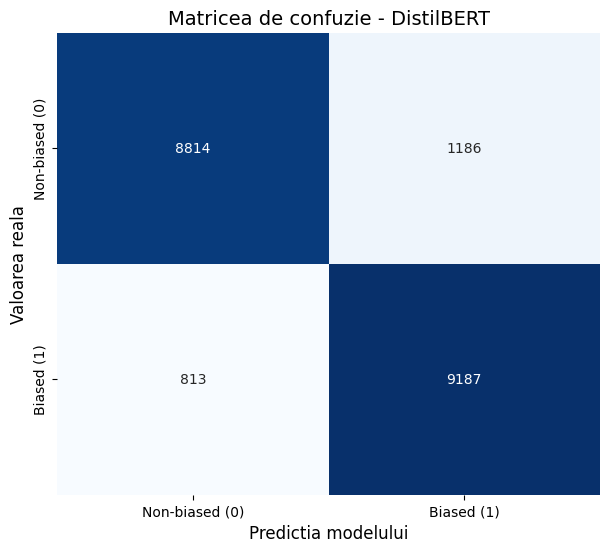

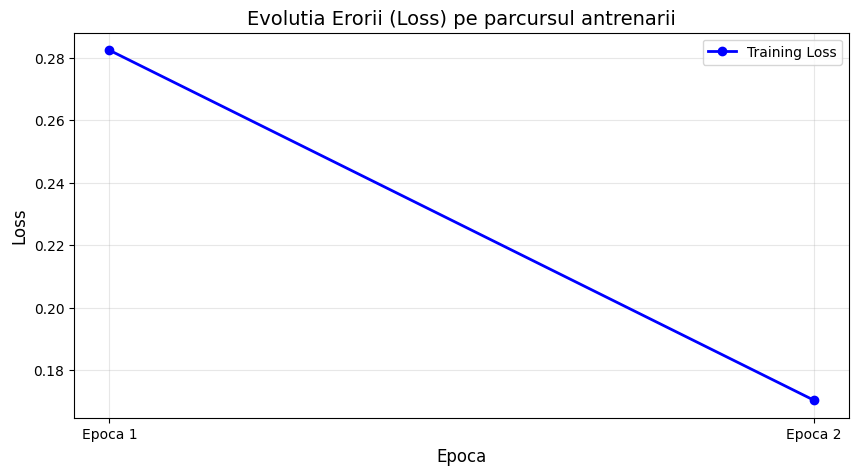

In [ ]:
#EVALUARE

model.eval()
predictions , true_labels = [], []

for batch in test_dataloader:
    batch = tuple(t.to(device) for t in batch)
    b_input_ids, b_input_mask, b_labels = batch

    with torch.no_grad():
        outputs = model(b_input_ids, attention_mask=b_input_mask)

    logits = outputs.logits
    logits = logits.detach().cpu().numpy()
    label_ids = b_labels.to('cpu').numpy()

    predictions.append(logits)
    true_labels.append(label_ids)

flat_predictions = [item for sublist in predictions for item in sublist]
flat_true_labels = [item for sublist in true_labels for item in sublist]
y_pred_distilbert = np.argmax(flat_predictions, axis=1).flatten()

acc_distilbert = accuracy_score(flat_true_labels, y_pred_distilbert)
print(f"Accuracy: {acc_distilbert}")
cm_distilbert = confusion_matrix(flat_true_labels, y_pred_distilbert)
print("Matrice de confuzie:")
print(cm_distilbert)
report_distilbert = classification_report(flat_true_labels, y_pred_distilbert, target_names=['Non-biased (0)', 'Biased (1)'])
print("Raport de clasificare:")
print(report_distilbert)

#VIZUALIZARE

plt.figure(figsize=(7, 6))
sns.heatmap(cm_distilbert, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Non-biased (0)', 'Biased (1)'],
            yticklabels=['Non-biased (0)', 'Biased (1)'])

plt.xlabel('Predictia modelului', fontsize=12)
plt.ylabel('Valoarea reala', fontsize=12)
plt.title('Matricea de confuzie - DistilBERT', fontsize=14)
plt.show()


plt.figure(figsize=(10, 5))
plt.plot(loss_values, 'b-o', linewidth=2, label='Training Loss')
plt.title('Evolutia Erorii (Loss) pe parcursul antrenarii', fontsize=14)
plt.xlabel('Epoca', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.xticks(range(len(loss_values)), [f"Epoca {i+1}" for i in range(len(loss_values))])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


###Interpretarea performantei

DistilBERT a atins o acuratete de 90.00%, o imbunatatire substantiala fata de regresie, ceea ce demonstreaza capacitatea transformerilor de a capta nuante semantice in text.

Precizia foarte buna pentru non-biased(0.92) indica faptul ca modelul identifica foarte bine textele obiective, reducand semnificativ alarmele false.

Recall-ul pentru biased (0.92) indica faptul ca modelului ii scapa foarte putine texte biased - doar 8%.

Scorul f1 pentru ambele clase arata un echilibru optim, modelul neavand o preferinta pentru una din clase

Matricea de confuzie releva 1186 de fals pozitive si 813 fals negative, o reducere semnificativa a erorilor fata de regresia liniara.


 COMPARATIE 
              Model  Accuracy  Precision (Biased)  Recall (Biased)  F1-Score (Biased)
Logistic Regression   0.85455                0.84             0.88               0.86
         DistilBERT   0.90005                0.89             0.92               0.90


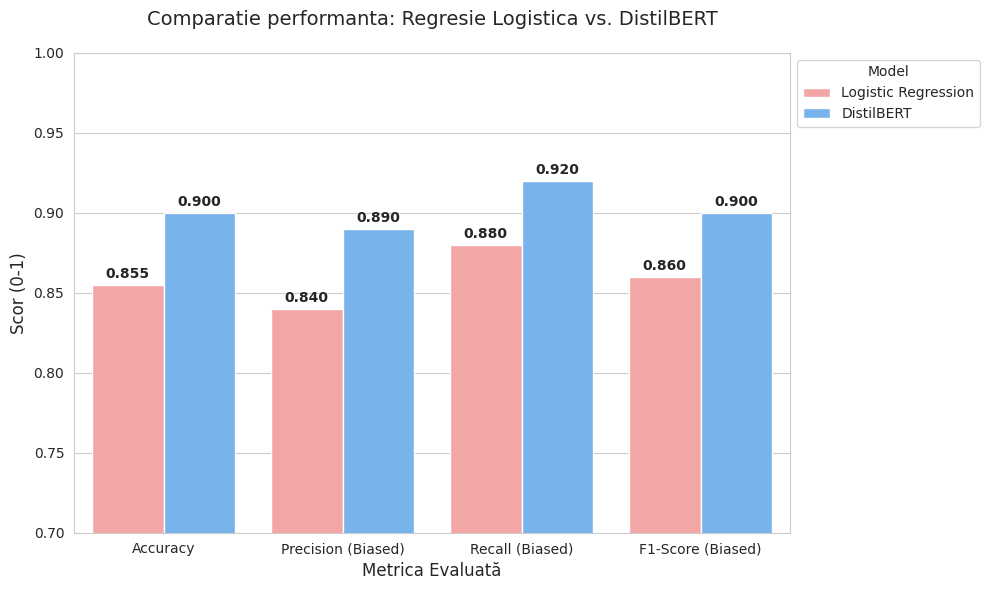

In [ ]:
#COMPARATIE MODELE

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'DistilBERT'],
    'Accuracy': [accuracy_logreg, acc_distilbert],
    'Precision (Biased)': [0.84, 0.89],
    'Recall (Biased)': [0.88, 0.92],
    'F1-Score (Biased)': [0.86, 0.90]
})

print("\n COMPARATIE ")
print(results.to_string(index=False))

#VIZUALIZARE COMPARATIE

results_melted = results.melt(id_vars="Model", var_name="Metrica", value_name="Scor")

plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

ax = sns.barplot(
    data=results_melted,
    x="Metrica",
    y="Scor",
    hue="Model",
    palette=["#ff9999", "#66b3ff"]
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10, fontweight='bold')

plt.title("Comparatie performanta: Regresie Logistica vs. DistilBERT", fontsize=14, pad=20)
plt.ylim(0.7, 1.0)
plt.ylabel("Scor (0-1)", fontsize=12)
plt.xlabel("Metrica", fontsize=12)
plt.legend(title='Model', loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()


#matrici de confuzie
tn_lr, fp_lr, fn_lr, tp_lr = cm_logreg.ravel()
tn_bert, fp_bert, fn_bert, tp_bert = cm_distilbert.ravel()

data_cm = [
    {'Model': 'Logistic Regression', 'Category': 'True Negative\n(Non-Biased Corect)', 'Count': tn_lr, 'Type': 'Corect'},
    {'Model': 'Logistic Regression', 'Category': 'True Positive\n(Biased Corect)', 'Count': tp_lr, 'Type': 'Corect'},
    {'Model': 'Logistic Regression', 'Category': 'False Positive\n(Alarme False)', 'Count': fp_lr, 'Type': 'Eroare'},
    {'Model': 'Logistic Regression', 'Category': 'False Negative\n(Bias Ratat)', 'Count': fn_lr, 'Type': 'Eroare'},

    {'Model': 'DistilBERT', 'Category': 'True Negative\n(Non-Biased Corect)', 'Count': tn_bert, 'Type': 'Corect'},
    {'Model': 'DistilBERT', 'Category': 'True Positive\n(Biased Corect)', 'Count': tp_bert, 'Type': 'Corect'},
    {'Model': 'DistilBERT', 'Category': 'False Positive\n(Alarme False)', 'Count': fp_bert, 'Type': 'Eroare'},
    {'Model': 'DistilBERT', 'Category': 'False Negative\n(Bias Ratat)', 'Count': fn_bert, 'Type': 'Eroare'},
]

df_cm_viz = pd.DataFrame(data_cm)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=df_cm_viz[df_cm_viz['Type'] == 'Corect'],
    x='Category', y='Count', hue='Model',
    palette=['#ff9999', '#66b3ff'], ax=axes[0]
)
axes[0].set_title('A. Comparatie Succese (True Positives & Negatives)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Numar de texte')
axes[0].grid(axis='y', alpha=0.3)


sns.barplot(
    data=df_cm_viz[df_cm_viz['Type'] == 'Eroare'],
    x='Category', y='Count', hue='Model',
    palette=['#ff9999', '#66b3ff'], ax=axes[1]
)
axes[1].set_title('B. Comparatie Erori (False Positives & Negatives)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Numar de texte')
axes[1].grid(axis='y', alpha=0.3)

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

###Comparatia modelelor

Comparand cele doua modele se observa o imbunatatire absoluta a performantei lui DistilBERT comparativ cu cea a Regresiei Liniare.

Se poate observa imbunatatirea in toate rezultatele:

-acuratete 90% vs 85.45%
-precizie pe biased 0.89 vs 0.84
-recall pe biased 0.92 vs 0.88
-f1 score pe biased 0.90 vs 0.86

Si reducerea erorilor:

-fals pozitive: 1186 vs 1677
-fals negativ: 813 vs 1232
-total erori: 1999 vs 2909


/tmp/ipython-input-3389695296.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df_compare.groupby('length_group')[['correct_logreg', 'correct_bert']].mean() * 100


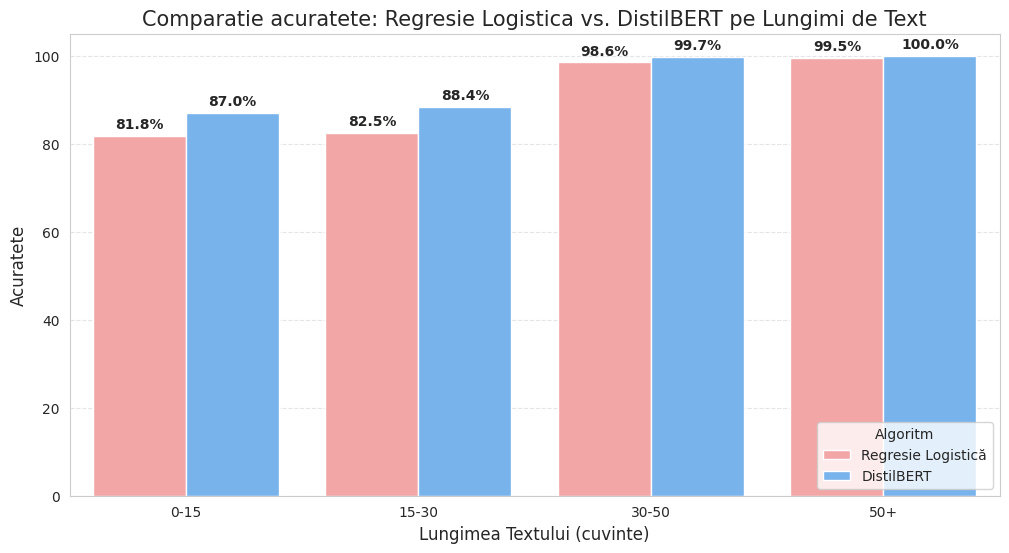


Numarul de texte pe categorii de lungime:
length_group
0-15     9918
15-30    6117
30-50    1389
50+      2576
Name: count, dtype: int64


In [ ]:
#COMARATIE PE LUNGIMI

df_compare = pd.DataFrame({
    'text': X_test_distilbert.values,
    'true_label': y_test.values,
    'pred_logreg': y_pred_logreg,
    'pred_bert': y_pred_distilbert
})

df_compare['word_count'] = df_compare['text'].apply(lambda x: len(str(x).split()))


df_compare['correct_logreg'] = df_compare['true_label'] == df_compare['pred_logreg']
df_compare['correct_bert'] = df_compare['true_label'] == df_compare['pred_bert']


bins = [0, 15, 30, 50, 100, 200, 1000]
labels_bins = ['0-15', '15-30', '30-50', '50-100', '100-200', '200+']

df_compare['length_group'] = pd.cut(df_compare['word_count'], bins=bins, labels=labels_bins)

grouped = df_compare.groupby('length_group')[['correct_logreg', 'correct_bert']].mean() * 100


grouped_melted = grouped.reset_index().melt(id_vars='length_group',
                                            var_name='Model',
                                            value_name='Acuratețe')


grouped_melted['Model'] = grouped_melted['Model'].replace({
    'correct_logreg': 'Regresie Logistică',
    'correct_bert': 'DistilBERT'
})

plt.figure(figsize=(12, 6))


ax = sns.barplot(data=grouped_melted, x='length_group', y='Acuratețe', hue='Model', palette=['#ff9999', '#66b3ff'])

plt.title('Comparatie Acuratete: Regresie Logistica vs. DistilBERT pe Lungimi de Text', fontsize=15)
plt.xlabel('Lungimea Textului (cuvinte)', fontsize=12)
plt.ylabel('Acuratete (%)', fontsize=12)
plt.ylim(0, 105)
plt.legend(title='Algoritm', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)


for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha = 'center', va = 'center',
                    xytext = (0, 8),
                    textcoords = 'offset points',
                    fontsize=10, fontweight='bold')

plt.show()

print("\nNumarul de texte pe categorii de lungime:")
print(df_compare['length_group'].value_counts().sort_index())

###Comparatie pe lungimi de text

Texte foarte scurte (0-15):
Texte scurte (15-30):
Texte medii (30-50): Ambele modele exceleaza
Texte lungi: Deoarece sunt foarte putine, sunt insuficiente statistic, deci nu se pot realiza concluzii ferme aici, acuratetea nereflectand performanta reala.

DistilBERT mentine un avantaj consistent pe toate lungimile de text. Cea mai mare diferenta exista la textele scurte si foarte scurte, unde intelegerea mai profunda face diferenta.

###Concluzii
Distributia inegala a lungimilor textelor din dataset este reprezentativa pentru continutul online real, ambele modele demonstrand capacitate de generalizare pe toate lungimile.

Regresia Logistica este un model de baza excelent, rapid si ieftin, bun pentru o filtrare in mare.

DistilBERT are o performanta mult mai buna, ceea ce ii ofera o aplicabilitate mult mai extinsa intr-un sistem real de detectare a bias-ului. Costul computational ridicat este justificat de capacitatea superioara de intelegere a contextului si nuantelor, ducand la o reducere drastica a alarmelor false si bias-ului ratat.